In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.stats import linregress
from woody_filter import woody, woody_stochastic
from tqdm import tqdm

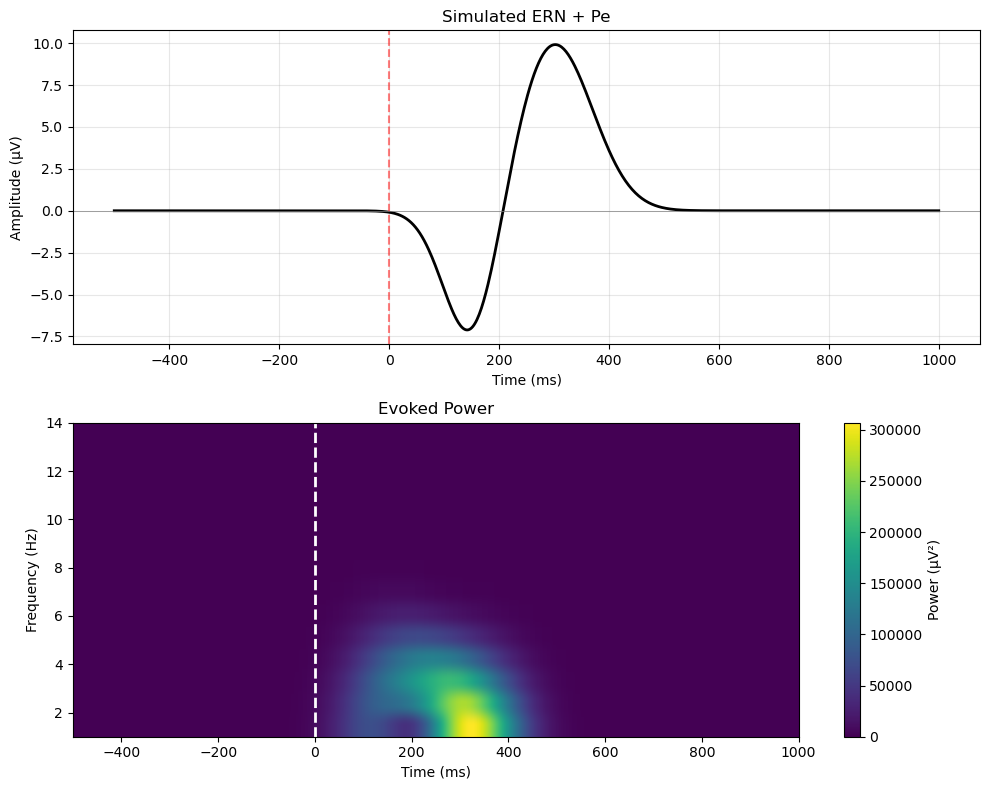

In [2]:
# Parameters
sfreq = 500
tmin, tmax = -0.5, 1.0
n_times = int((tmax - tmin) * sfreq) + 1
times = np.linspace(tmin, tmax, n_times)

# ERN + Pe parameters
ern_peak_time, ern_amplitude, ern_width = 0.15, -8, 0.05
pe_peak_time, pe_amplitude, pe_width = 0.3, 10, 0.07

ern = ern_amplitude * np.exp(-0.5 * ((times - ern_peak_time) / ern_width) ** 2)
pe = pe_amplitude * np.exp(-0.5 * ((times - pe_peak_time) / pe_width) ** 2)
erp = ern + pe

# TFR of clean ERP
freqs = np.arange(1, 15, 1)
n_cycles = freqs / 2.0

tfr = np.zeros((len(freqs), len(times)))
for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
    wavelet_duration = min(3 * n_cycle / freq, 0.5)
    wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
    wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
    convolved = np.convolve(erp, wavelet, mode='same')
    tfr[idx, :] = np.abs(convolved) ** 2

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))
ax1.plot(times * 1000, erp, 'k', linewidth=2)
ax1.axvline(0, color='r', linestyle='--', alpha=0.5)
ax1.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax1.set_xlabel('Time (ms)'); ax1.set_ylabel('Amplitude (µV)')
ax1.set_title('Simulated ERN + Pe'); ax1.grid(alpha=0.3)

im = ax2.imshow(tfr, aspect='auto', origin='lower', extent=[times[0]*1000, times[-1]*1000, freqs[0], freqs[-1]])
ax2.axvline(0, color='white', linestyle='--', linewidth=2)
ax2.set_xlabel('Time (ms)'); ax2.set_ylabel('Frequency (Hz)')
ax2.set_title('Evoked Power')
plt.colorbar(im, ax=ax2, label='Power (µV²)')
plt.tight_layout()

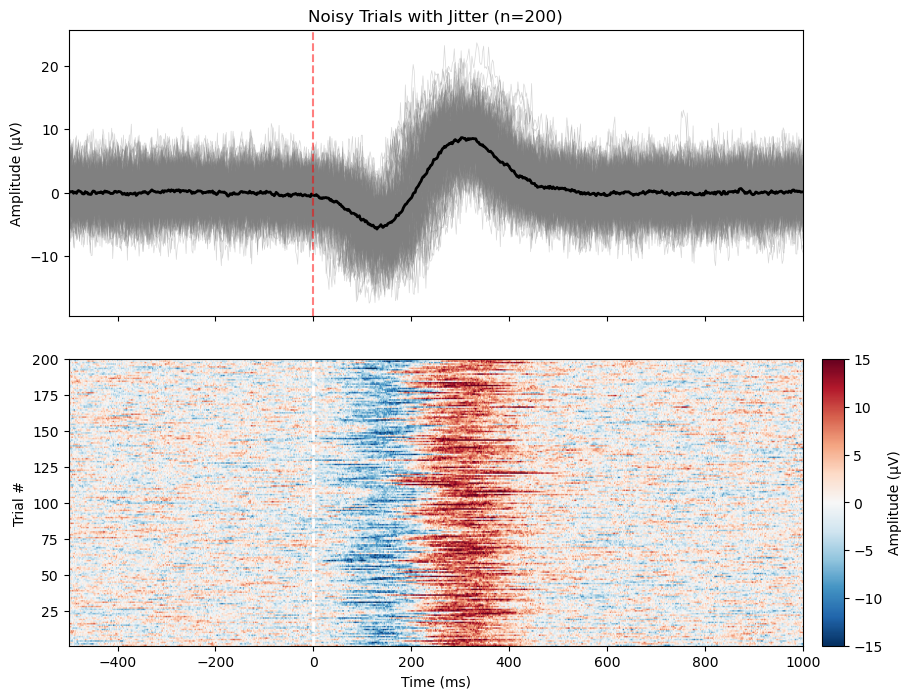

In [23]:
def generate_pink_noise(n_samples):
    white = np.random.randn(n_samples)
    fft_white = np.fft.rfft(white)
    freqs_fft = np.fft.rfftfreq(n_samples)
    freqs_fft[0] = 1
    pink_fft = fft_white / np.sqrt(freqs_fft)
    pink = np.fft.irfft(pink_fft, n=n_samples)
    return pink / np.std(pink)

n_trials = 200
jitter_sd = 0.035
noise_amplitude = 3
amplitude_jitter_sd = 0.2

trials = np.zeros((n_trials, n_times))
true_jitters = np.zeros(n_trials)

for trial in range(n_trials):
    onset_jitter = np.clip(np.random.normal(0, jitter_sd), -ern_peak_time, None)
    true_jitters[trial] = onset_jitter
    
    ern_amp = ern_amplitude * np.random.lognormal(0, amplitude_jitter_sd)
    pe_amp = pe_amplitude * np.random.lognormal(0, amplitude_jitter_sd)
    
    ern_trial = ern_amp * np.exp(-0.5 * ((times - (ern_peak_time + onset_jitter)) / ern_width) ** 2)
    pe_trial = pe_amp * np.exp(-0.5 * ((times - (pe_peak_time + onset_jitter)) / pe_width) ** 2)
    noise = generate_pink_noise(n_times) * noise_amplitude
    
    trials[trial, :] = ern_trial + pe_trial + noise

grand_avg = trials.mean(axis=0)

fig = plt.figure(figsize=(10, 8))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 0.03], hspace=0.15, wspace=0.05)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[1, 0], sharex=ax1)
cax = fig.add_subplot(gs[1, 1])  # dedicated colorbar axis, aligned to ax2 only

ax1.plot(times * 1000, trials.T, 'gray', alpha=0.3, linewidth=0.5)
ax1.plot(times * 1000, grand_avg, 'k', linewidth=2)
ax1.axvline(0, color='r', linestyle='--', alpha=0.5)
ax1.set_ylabel('Amplitude (µV)')
ax1.set_title(f'Noisy Trials with Jitter (n={n_trials})')
ax1.tick_params(labelbottom=False)

im = ax2.imshow(trials, aspect='auto', origin='lower',
                extent=[tmin*1000, tmax*1000, 1, n_trials],
                cmap='RdBu_r', vmin=-15, vmax=15)
ax2.axvline(0, color='white', linestyle='--', linewidth=2)
ax2.set_xlabel('Time (ms)')
ax2.set_ylabel('Trial #')

fig.colorbar(im, cax=cax, label='Amplitude (µV)')

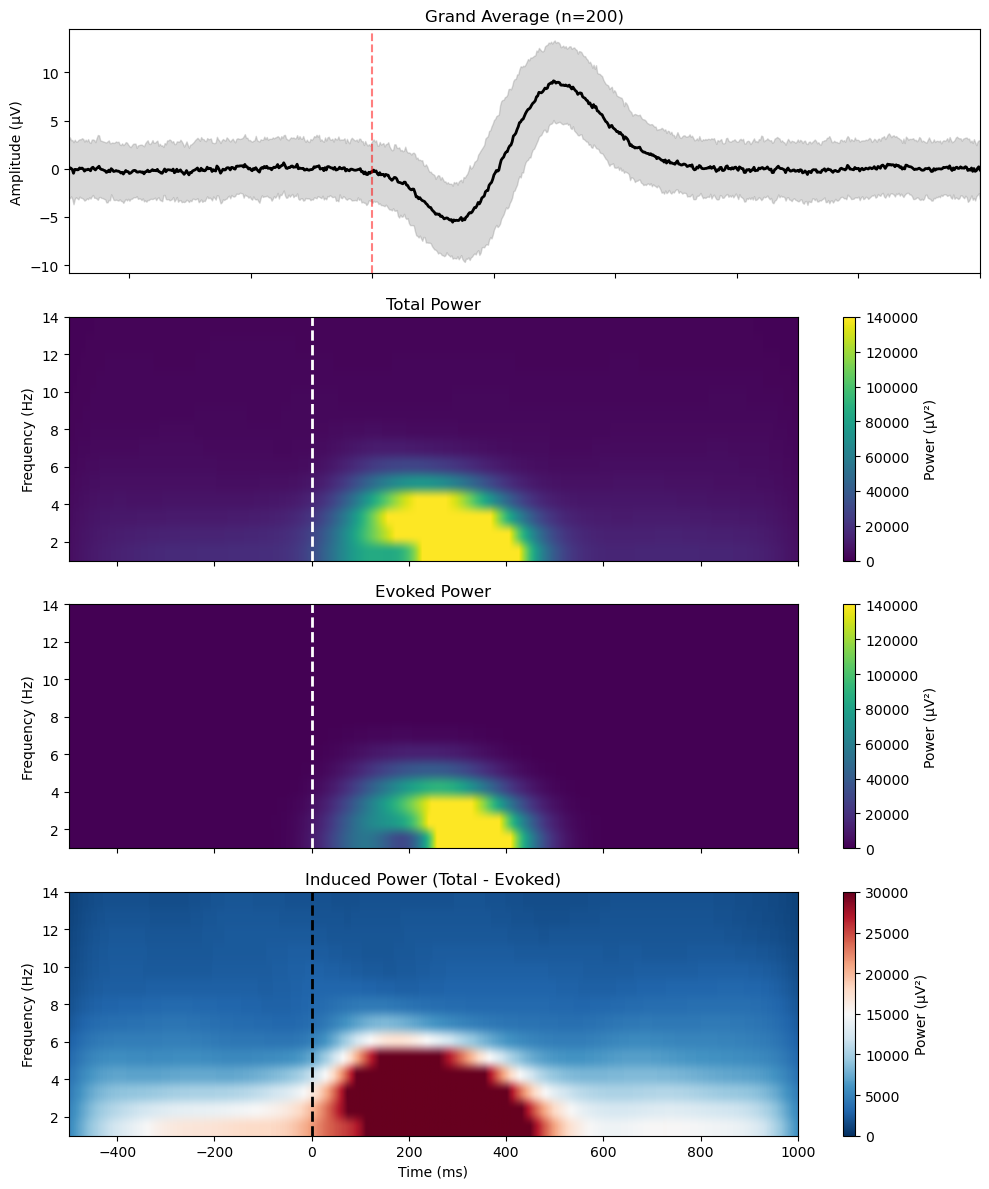

In [4]:
grand_avg = trials.mean(axis=0)
sd = trials.std(axis=0)

freqs = np.arange(1, 15, 1)
n_cycles = freqs / 2.0

# Evoked power
tfr_evoked = np.zeros((len(freqs), len(times)))
for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
    wavelet_duration = min(3 * n_cycle / freq, 0.5)
    wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
    wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
    convolved = np.convolve(grand_avg, wavelet, mode='same')
    tfr_evoked[idx, :] = np.abs(convolved) ** 2

# Total power
tfr_total = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(trials[trial, :], wavelet, mode='same')
        tfr_total[idx, :] += np.abs(convolved) ** 2
tfr_total /= n_trials

tfr_induced = tfr_total - tfr_evoked

fig, axes = plt.subplots(4, 1, figsize=(10, 12), sharex=True)
axes[0].plot(times * 1000, grand_avg, 'k', linewidth=2)
axes[0].fill_between(times * 1000, grand_avg - sd, grand_avg + sd, color='gray', alpha=0.3)
axes[0].axvline(0, color='r', linestyle='--', alpha=0.5)
axes[0].set_ylabel('Amplitude (µV)'); axes[0].set_title(f'Grand Average (n={n_trials})')

im1 = axes[1].imshow(tfr_total, aspect='auto', origin='lower', extent=[tmin*1000, tmax*1000, freqs[0], freqs[-1]], vmin=0, vmax=140000)
axes[1].axvline(0, color='white', linestyle='--', linewidth=2)
axes[1].set_ylabel('Frequency (Hz)'); axes[1].set_title('Total Power')
plt.colorbar(im1, ax=axes[1], label='Power (µV²)')

im2 = axes[2].imshow(tfr_evoked, aspect='auto', origin='lower', extent=[tmin*1000, tmax*1000, freqs[0], freqs[-1]], vmin=0, vmax=140000)
axes[2].axvline(0, color='white', linestyle='--', linewidth=2)
axes[2].set_ylabel('Frequency (Hz)'); axes[2].set_title('Evoked Power')
plt.colorbar(im2, ax=axes[2], label='Power (µV²)')

im3 = axes[3].imshow(tfr_induced, aspect='auto', origin='lower', extent=[tmin*1000, tmax*1000, freqs[0], freqs[-1]], cmap='RdBu_r', vmin=0, vmax=30000)
axes[3].axvline(0, color='black', linestyle='--', linewidth=2)
axes[3].set_xlabel('Time (ms)'); axes[3].set_ylabel('Frequency (Hz)'); axes[3].set_title('Induced Power (Total - Evoked)')
plt.colorbar(im3, ax=axes[3], label='Power (µV²)')
plt.tight_layout()

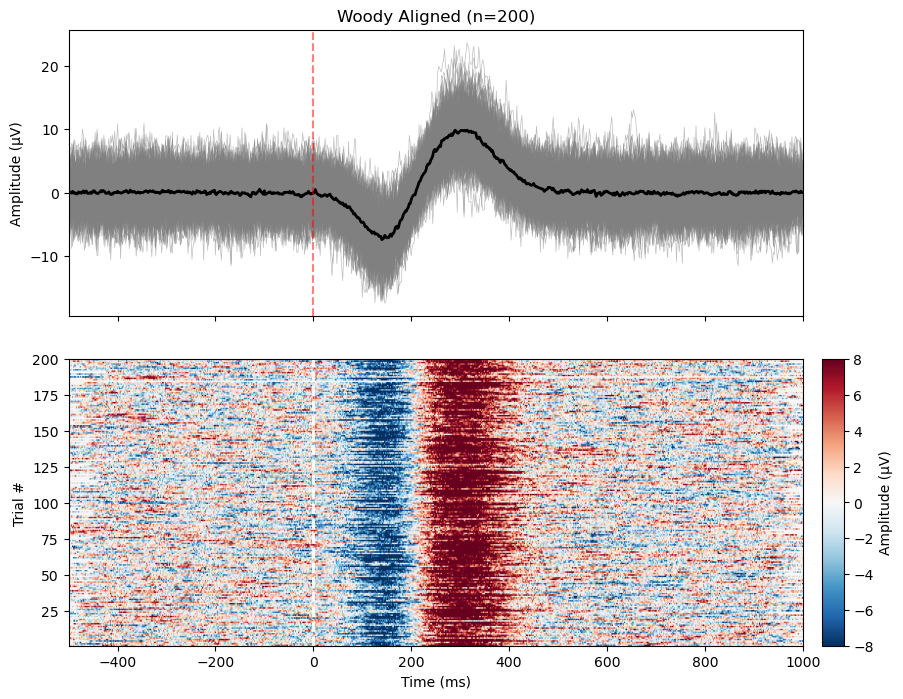

In [24]:
trials_T = trials.T
aligned_avg, detected_lags = woody(trials_T, tol=0.1, max_it=100, est_mthd='woody', xcorr_mthd='unbiased')

aligned_trials = np.zeros_like(trials)
for i in range(n_trials):
    lag = detected_lags[i]
    if lag > 0:
        aligned_trials[i, :] = np.concatenate([trials[i, lag:], np.zeros(lag)])
    elif lag < 0:
        aligned_trials[i, :] = np.concatenate([np.zeros(-lag), trials[i, :lag]])
    else:
        aligned_trials[i, :] = trials[i, :]

grand_avg_aligned = aligned_trials.mean(axis=0)

fig = plt.figure(figsize=(10, 8))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 0.03], hspace=0.15, wspace=0.05)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[1, 0], sharex=ax1)
cax = fig.add_subplot(gs[1, 1])

ax1.plot(times * 1000, aligned_trials.T, 'gray', alpha=0.5, linewidth=0.5)
ax1.plot(times * 1000, grand_avg_aligned, 'k', linewidth=2)
ax1.axvline(0, color='r', linestyle='--', alpha=0.5)
ax1.set_ylabel('Amplitude (µV)')
ax1.set_title(f'Woody Aligned (n={n_trials})')
ax1.tick_params(labelbottom=False)

im = ax2.imshow(aligned_trials, aspect='auto', origin='lower',
                extent=[tmin*1000, tmax*1000, 1, n_trials],
                cmap='RdBu_r', vmin=-8, vmax=8)
ax2.axvline(0, color='white', linestyle='--', linewidth=2)
ax2.set_xlabel('Time (ms)')
ax2.set_ylabel('Trial #')

fig.colorbar(im, cax=cax, label='Amplitude (µV)')

Correlation: 0.401


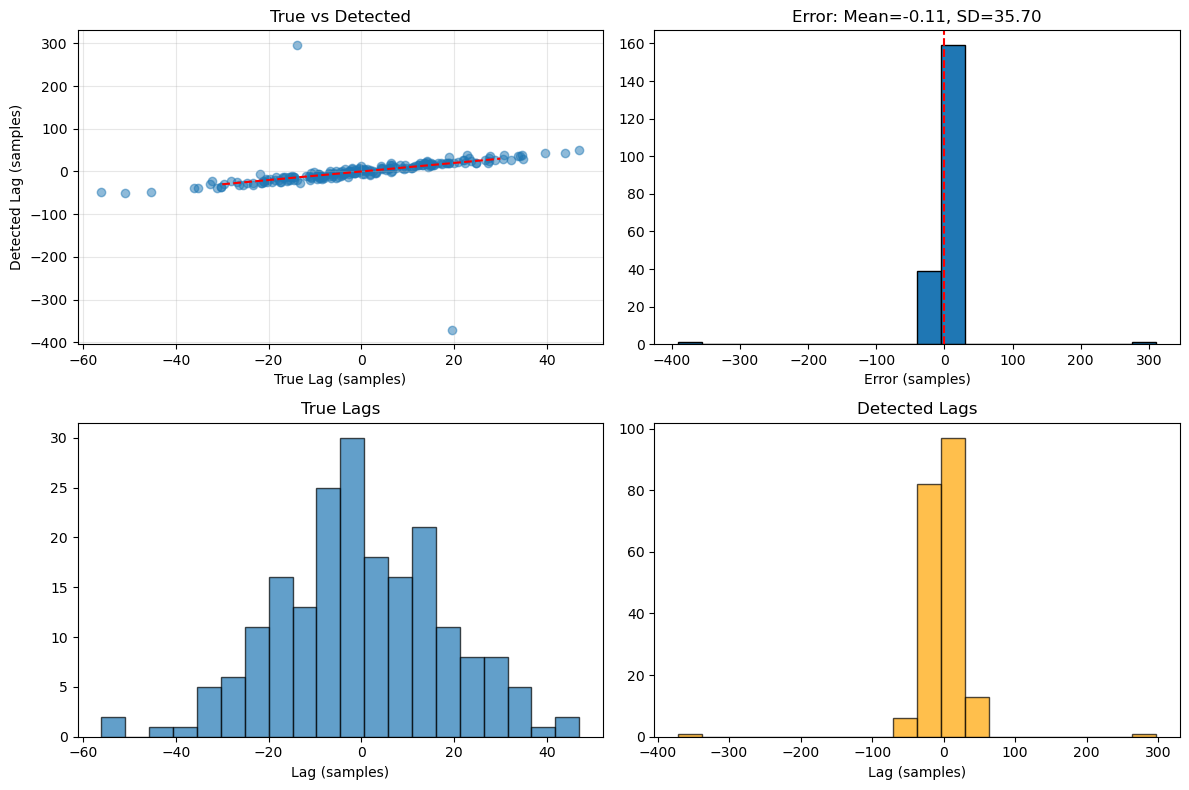

In [25]:
true_lags_samples = true_jitters * sfreq

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].scatter(true_lags_samples, detected_lags, alpha=0.5)
axes[0, 0].plot([-30, 30], [-30, 30], 'r--')
axes[0, 0].set_xlabel('True Lag (samples)'); axes[0, 0].set_ylabel('Detected Lag (samples)')
axes[0, 0].set_title('True vs Detected'); axes[0, 0].grid(alpha=0.3)

error = detected_lags - true_lags_samples
axes[0, 1].hist(error, bins=20, edgecolor='black')
axes[0, 1].axvline(0, color='r', linestyle='--')
axes[0, 1].set_xlabel('Error (samples)'); axes[0, 1].set_title(f'Error: Mean={error.mean():.2f}, SD={error.std():.2f}')

axes[1, 0].hist(true_lags_samples, bins=20, edgecolor='black', alpha=0.7)
axes[1, 0].set_xlabel('Lag (samples)'); axes[1, 0].set_title('True Lags')

axes[1, 1].hist(detected_lags, bins=20, edgecolor='black', alpha=0.7, color='orange')
axes[1, 1].set_xlabel('Lag (samples)'); axes[1, 1].set_title('Detected Lags')

plt.tight_layout()
print(f'Correlation: {np.corrcoef(true_lags_samples, detected_lags)[0,1]:.3f}')

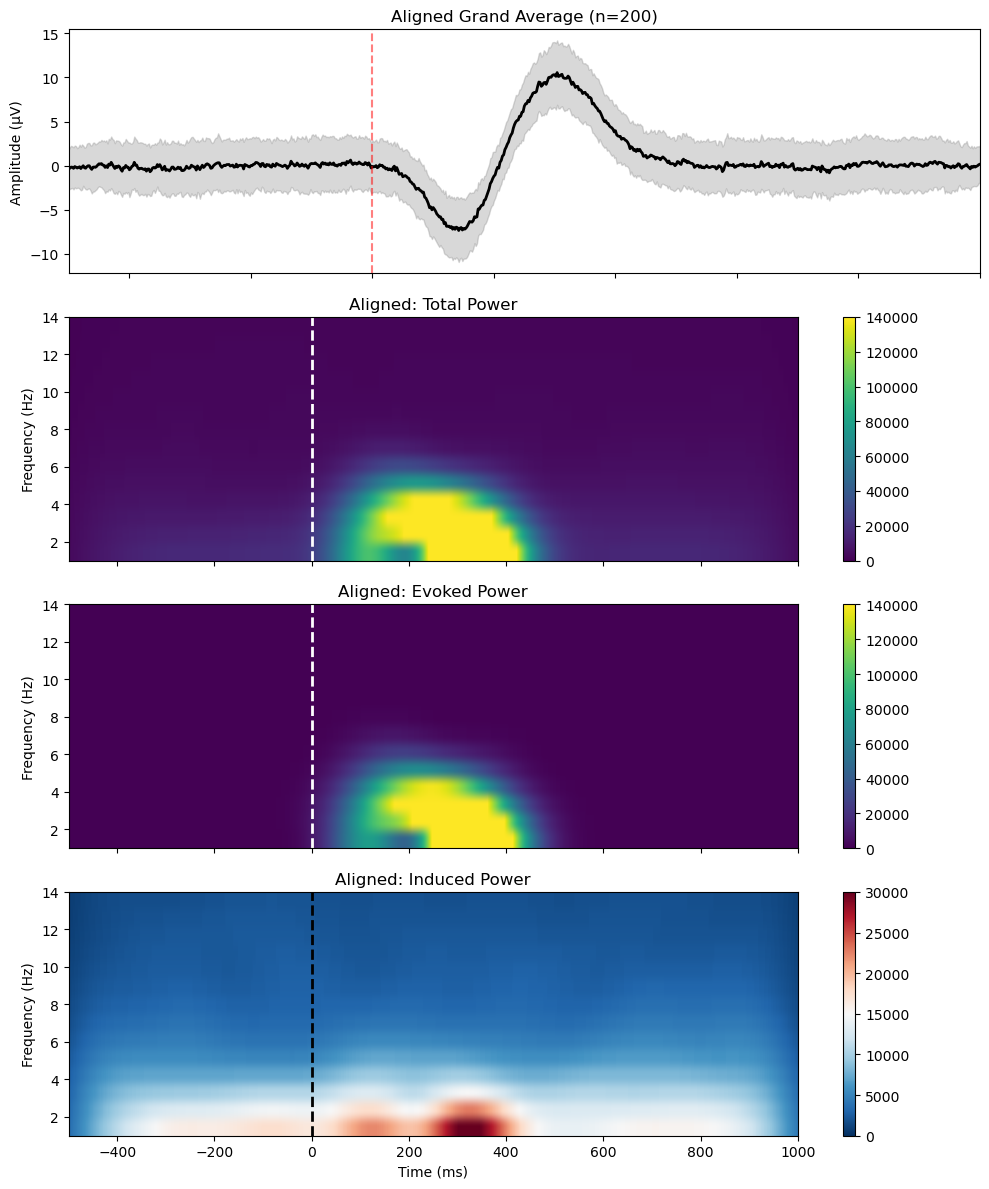

In [7]:
grand_avg_aligned = aligned_trials.mean(axis=0)
sd_aligned = aligned_trials.std(axis=0)

freqs = np.arange(1, 15, 1)
n_cycles = freqs / 2.0

tfr_evoked_aligned = np.zeros((len(freqs), len(times)))
for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
    wavelet_duration = min(3 * n_cycle / freq, 0.5)
    wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
    wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
    convolved = np.convolve(grand_avg_aligned, wavelet, mode='same')
    tfr_evoked_aligned[idx, :] = np.abs(convolved) ** 2

tfr_total_aligned = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(aligned_trials[trial, :], wavelet, mode='same')
        tfr_total_aligned[idx, :] += np.abs(convolved) ** 2
tfr_total_aligned /= n_trials

tfr_induced_aligned = tfr_total_aligned - tfr_evoked_aligned

fig, axes = plt.subplots(4, 1, figsize=(10, 12), sharex=True)
axes[0].plot(times * 1000, grand_avg_aligned, 'k', linewidth=2)
axes[0].fill_between(times * 1000, grand_avg_aligned - sd_aligned, grand_avg_aligned + sd_aligned, color='gray', alpha=0.3)
axes[0].axvline(0, color='r', linestyle='--', alpha=0.5)
axes[0].set_ylabel('Amplitude (µV)'); axes[0].set_title(f'Aligned Grand Average (n={n_trials})')

im1 = axes[1].imshow(tfr_total_aligned, aspect='auto', origin='lower', extent=[tmin*1000, tmax*1000, freqs[0], freqs[-1]], vmin=0, vmax=140000)
axes[1].axvline(0, color='white', linestyle='--', linewidth=2)
axes[1].set_ylabel('Frequency (Hz)'); axes[1].set_title('Aligned: Total Power')
plt.colorbar(im1, ax=axes[1])

im2 = axes[2].imshow(tfr_evoked_aligned, aspect='auto', origin='lower', extent=[tmin*1000, tmax*1000, freqs[0], freqs[-1]], vmin=0, vmax=140000)
axes[2].axvline(0, color='white', linestyle='--', linewidth=2)
axes[2].set_ylabel('Frequency (Hz)'); axes[2].set_title('Aligned: Evoked Power')
plt.colorbar(im2, ax=axes[2])

im3 = axes[3].imshow(tfr_induced_aligned, aspect='auto', origin='lower', extent=[tmin*1000, tmax*1000, freqs[0], freqs[-1]], cmap='RdBu_r', vmin=0, vmax=30000)
axes[3].axvline(0, color='black', linestyle='--', linewidth=2)
axes[3].set_xlabel('Time (ms)'); axes[3].set_ylabel('Frequency (Hz)'); axes[3].set_title('Aligned: Induced Power')
plt.colorbar(im3, ax=axes[3])
plt.tight_layout()

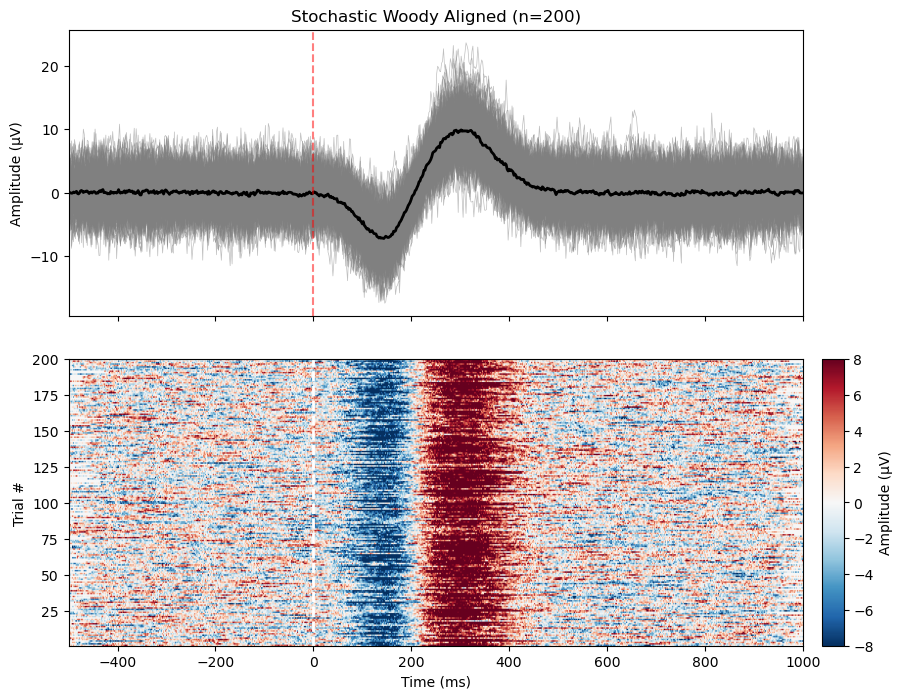

In [26]:
aligned_avg_stoch, detected_lags_stoch, best_corr = woody_stochastic(
    trials_T, tol=0.1, max_it=100, xcorr_mthd='unbiased', max_lag_init=10, max_shift=50
)

aligned_trials_stoch = np.zeros_like(trials)
for i in range(n_trials):
    lag = detected_lags_stoch[i]
    if lag > 0:
        aligned_trials_stoch[i, :] = np.concatenate([trials[i, lag:], np.zeros(lag)])
    elif lag < 0:
        aligned_trials_stoch[i, :] = np.concatenate([np.zeros(-lag), trials[i, :lag]])
    else:
        aligned_trials_stoch[i, :] = trials[i, :]

grand_avg_stoch = aligned_trials_stoch.mean(axis=0)

fig = plt.figure(figsize=(10, 8))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 0.03], hspace=0.15, wspace=0.05)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[1, 0], sharex=ax1)
cax = fig.add_subplot(gs[1, 1])

ax1.plot(times * 1000, aligned_trials_stoch.T, 'gray', alpha=0.5, linewidth=0.5)
ax1.plot(times * 1000, grand_avg_stoch, 'k', linewidth=2)
ax1.axvline(0, color='r', linestyle='--', alpha=0.5)
ax1.set_ylabel('Amplitude (µV)')
ax1.set_title(f'Stochastic Woody Aligned (n={n_trials})')
ax1.tick_params(labelbottom=False)

im = ax2.imshow(aligned_trials_stoch, aspect='auto', origin='lower',
                extent=[tmin*1000, tmax*1000, 1, n_trials],
                cmap='RdBu_r', vmin=-8, vmax=8)
ax2.axvline(0, color='white', linestyle='--', linewidth=2)
ax2.set_xlabel('Time (ms)')
ax2.set_ylabel('Trial #')

fig.colorbar(im, cax=cax, label='Amplitude (µV)')

Correlation: 0.960


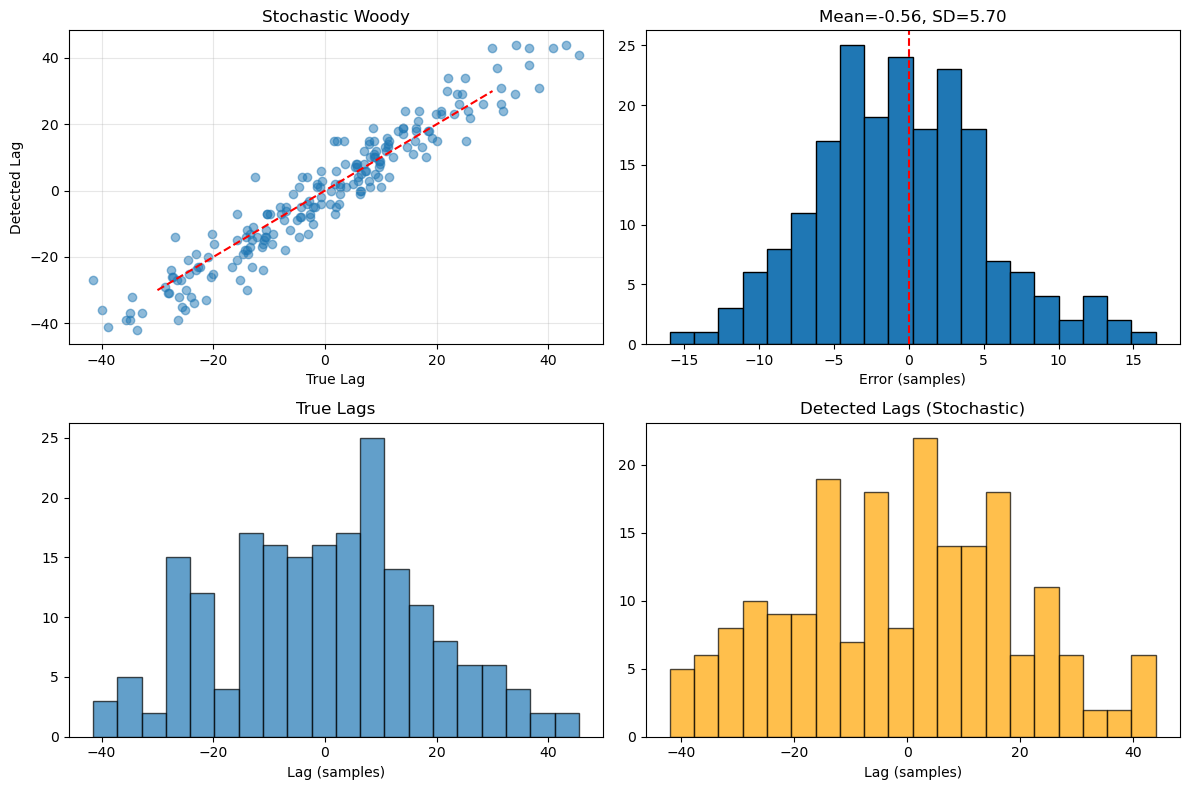

In [9]:
true_lags_samples = true_jitters * sfreq

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].scatter(true_lags_samples, detected_lags_stoch, alpha=0.5)
axes[0, 0].plot([-30, 30], [-30, 30], 'r--')
axes[0, 0].set_xlabel('True Lag'); axes[0, 0].set_ylabel('Detected Lag')
axes[0, 0].set_title('Stochastic Woody'); axes[0, 0].grid(alpha=0.3)

error_stoch = detected_lags_stoch - true_lags_samples
axes[0, 1].hist(error_stoch, bins=20, edgecolor='black')
axes[0, 1].axvline(0, color='r', linestyle='--')
axes[0, 1].set_xlabel('Error (samples)'); axes[0, 1].set_title(f'Mean={error_stoch.mean():.2f}, SD={error_stoch.std():.2f}')

axes[1, 0].hist(true_lags_samples, bins=20, edgecolor='black', alpha=0.7)
axes[1, 0].set_xlabel('Lag (samples)'); axes[1, 0].set_title('True Lags')

axes[1, 1].hist(detected_lags_stoch, bins=20, edgecolor='black', alpha=0.7, color='orange')
axes[1, 1].set_xlabel('Lag (samples)'); axes[1, 1].set_title('Detected Lags (Stochastic)')

plt.tight_layout()
print(f'Correlation: {np.corrcoef(true_lags_samples, detected_lags_stoch)[0,1]:.3f}')

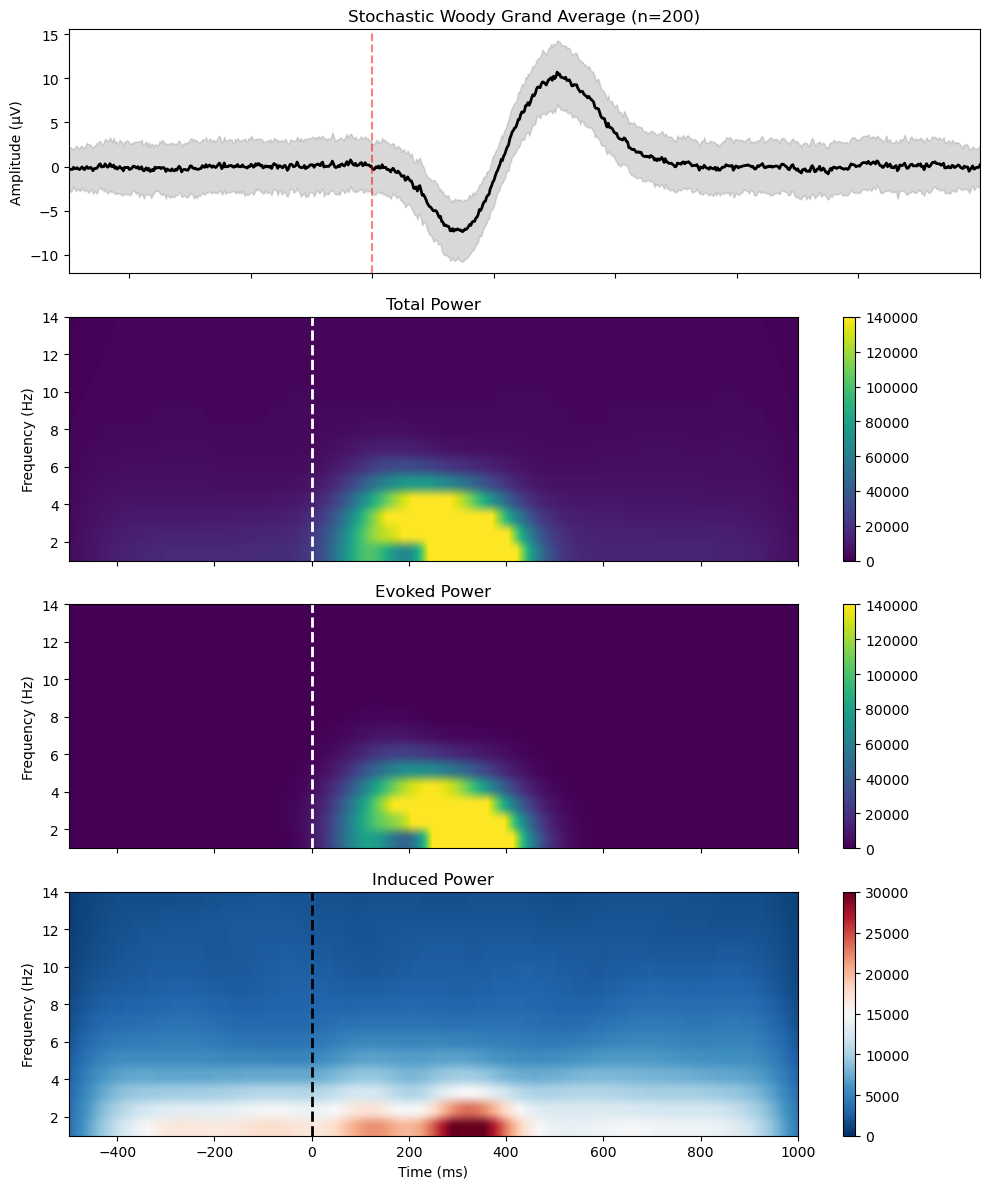

In [10]:
grand_avg_stoch = aligned_trials_stoch.mean(axis=0)
sd_stoch = aligned_trials_stoch.std(axis=0)

freqs = np.arange(1, 15, 1)
n_cycles = freqs / 2.0

tfr_evoked_stoch = np.zeros((len(freqs), len(times)))
for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
    wavelet_duration = min(3 * n_cycle / freq, 0.5)
    wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
    wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
    convolved = np.convolve(grand_avg_stoch, wavelet, mode='same')
    tfr_evoked_stoch[idx, :] = np.abs(convolved) ** 2

tfr_total_stoch = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(aligned_trials_stoch[trial, :], wavelet, mode='same')
        tfr_total_stoch[idx, :] += np.abs(convolved) ** 2
tfr_total_stoch /= n_trials

tfr_induced_stoch = tfr_total_stoch - tfr_evoked_stoch

fig, axes = plt.subplots(4, 1, figsize=(10, 12), sharex=True)
axes[0].plot(times * 1000, grand_avg_stoch, 'k', linewidth=2)
axes[0].fill_between(times * 1000, grand_avg_stoch - sd_stoch, grand_avg_stoch + sd_stoch, color='gray', alpha=0.3)
axes[0].axvline(0, color='r', linestyle='--', alpha=0.5)
axes[0].set_ylabel('Amplitude (µV)'); axes[0].set_title(f'Stochastic Woody Grand Average (n={n_trials})')

im1 = axes[1].imshow(tfr_total_stoch, aspect='auto', origin='lower', extent=[tmin*1000, tmax*1000, freqs[0], freqs[-1]], vmin=0, vmax=140000)
axes[1].axvline(0, color='white', linestyle='--', linewidth=2)
axes[1].set_ylabel('Frequency (Hz)'); axes[1].set_title('Total Power')
plt.colorbar(im1, ax=axes[1])

im2 = axes[2].imshow(tfr_evoked_stoch, aspect='auto', origin='lower', extent=[tmin*1000, tmax*1000, freqs[0], freqs[-1]], vmin=0, vmax=140000)
axes[2].axvline(0, color='white', linestyle='--', linewidth=2)
axes[2].set_ylabel('Frequency (Hz)'); axes[2].set_title('Evoked Power')
plt.colorbar(im2, ax=axes[2])

im3 = axes[3].imshow(tfr_induced_stoch, aspect='auto', origin='lower', extent=[tmin*1000, tmax*1000, freqs[0], freqs[-1]], cmap='RdBu_r', vmin=0, vmax=30000)
axes[3].axvline(0, color='black', linestyle='--', linewidth=2)
axes[3].set_xlabel('Time (ms)'); axes[3].set_ylabel('Frequency (Hz)'); axes[3].set_title('Induced Power')
plt.colorbar(im3, ax=axes[3])
plt.tight_layout()

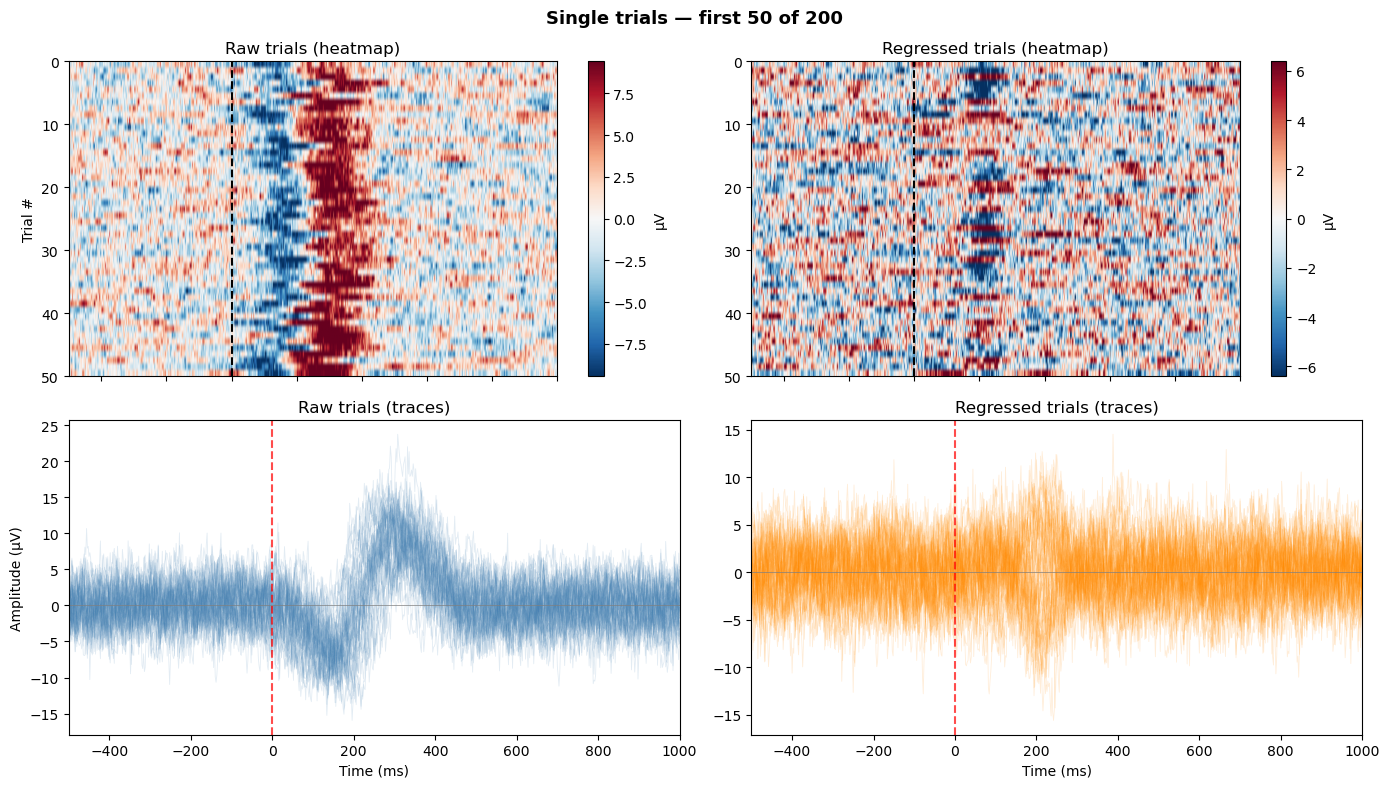

In [22]:
# ── Single-trial visualisation ──────────────────────────────────────────────
n_show = min(n_trials, 50)
trial_idx = np.arange(n_show)

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)

# ── Raw trials ────────────────────────────────────────────────────────────
vmax = np.percentile(np.abs(trials[:n_show]), 95)
im0 = axes[0, 0].imshow(
    trials[:n_show],
    aspect='auto', origin='upper',
    extent=[tmin * 1000, tmax * 1000, n_show, 0],
    cmap='RdBu_r', vmin=-vmax, vmax=vmax
)
axes[0, 0].axvline(0, color='k', linestyle='--', linewidth=1.5)
axes[0, 0].set_ylabel('Trial #')
axes[0, 0].set_title('Raw trials (heatmap)')
plt.colorbar(im0, ax=axes[0, 0], label='µV')

for i in trial_idx:
    axes[1, 0].plot(times * 1000, trials[i], color='steelblue', alpha=0.15, linewidth=0.6)
axes[1, 0].axvline(0, color='r', linestyle='--', alpha=0.7)
axes[1, 0].axhline(0, color='gray', linewidth=0.5)
axes[1, 0].set_xlabel('Time (ms)'); axes[1, 0].set_ylabel('Amplitude (µV)')
axes[1, 0].set_title('Raw trials (traces)')

# ── Regressed trials ──────────────────────────────────────────────────────
vmax_r = np.percentile(np.abs(trials_regressed[:n_show]), 95)
im1 = axes[0, 1].imshow(
    trials_regressed[:n_show],
    aspect='auto', origin='upper',
    extent=[tmin * 1000, tmax * 1000, n_show, 0],
    cmap='RdBu_r', vmin=-vmax_r, vmax=vmax_r
)
axes[0, 1].axvline(0, color='k', linestyle='--', linewidth=1.5)
axes[0, 1].set_title('Regressed trials (heatmap)')
plt.colorbar(im1, ax=axes[0, 1], label='µV')

for i in trial_idx:
    axes[1, 1].plot(times * 1000, trials_regressed[i], color='darkorange', alpha=0.15, linewidth=0.6)
axes[1, 1].axvline(0, color='r', linestyle='--', alpha=0.7)
axes[1, 1].axhline(0, color='gray', linewidth=0.5)
axes[1, 1].set_xlabel('Time (ms)')
axes[1, 1].set_title('Regressed trials (traces)')

fig.suptitle(f'Single trials — first {n_show} of {n_trials}', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

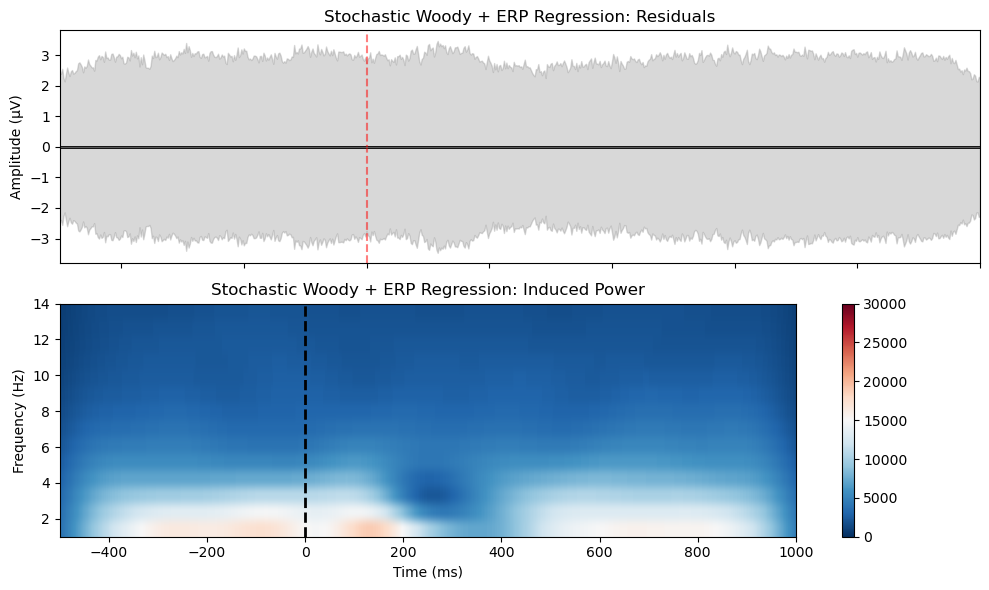

In [12]:
# Stochastic Woody + ERP regression
grand_avg_stoch = aligned_trials_stoch.mean(axis=0)

trials_stoch_reg = np.zeros_like(aligned_trials_stoch)
for t_idx in range(n_trials):
    slope, intercept, _, _, _ = linregress(grand_avg_stoch, aligned_trials_stoch[t_idx, :])
    trials_stoch_reg[t_idx, :] = aligned_trials_stoch[t_idx, :] - (intercept + slope * grand_avg_stoch)

grand_avg_stoch_reg = trials_stoch_reg.mean(axis=0)
sd_stoch_reg = trials_stoch_reg.std(axis=0)

tfr_induced_stoch_reg = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(trials_stoch_reg[trial, :], wavelet, mode='same')
        tfr_induced_stoch_reg[idx, :] += np.abs(convolved) ** 2
tfr_induced_stoch_reg /= n_trials

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax1.plot(times * 1000, grand_avg_stoch_reg, 'k', linewidth=2)
ax1.fill_between(times * 1000, grand_avg_stoch_reg - sd_stoch_reg, grand_avg_stoch_reg + sd_stoch_reg, color='gray', alpha=0.3)
ax1.axvline(0, color='r', linestyle='--', alpha=0.5); ax1.axhline(0, color='gray', linewidth=0.5)
ax1.set_ylabel('Amplitude (µV)'); ax1.set_title('Stochastic Woody + ERP Regression: Residuals')

im = ax2.imshow(tfr_induced_stoch_reg, aspect='auto', origin='lower', extent=[tmin*1000, tmax*1000, freqs[0], freqs[-1]], cmap='RdBu_r', vmin=0, vmax=30000)
ax2.axvline(0, color='black', linestyle='--', linewidth=2)
ax2.set_xlabel('Time (ms)'); ax2.set_ylabel('Frequency (Hz)'); ax2.set_title('Stochastic Woody + ERP Regression: Induced Power')
plt.colorbar(im, ax=ax2)
plt.tight_layout()

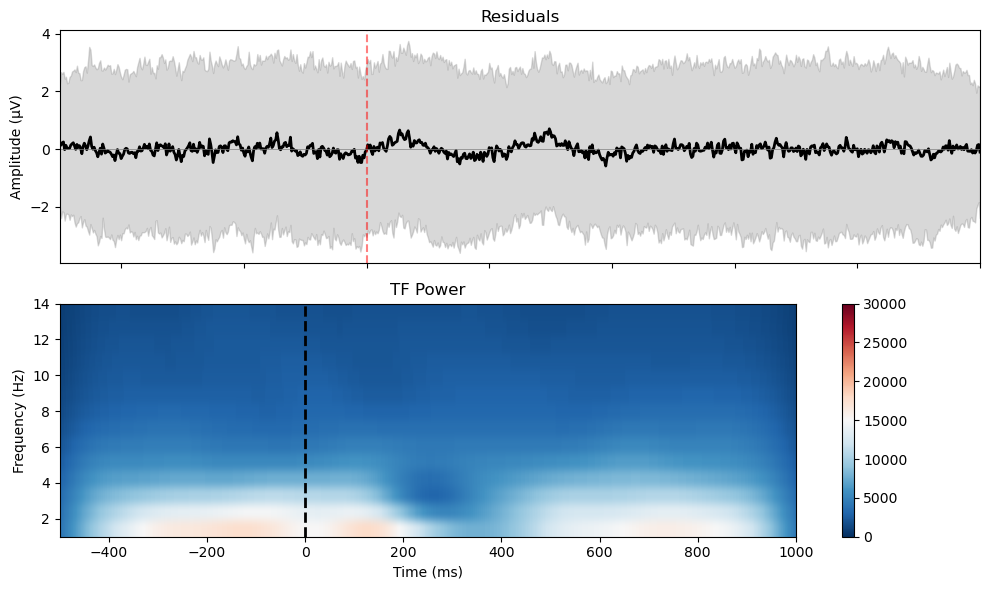

In [20]:
# Stochastic Woody + ERP regression + Reinstate lags
grand_avg_stoch = aligned_trials_stoch.mean(axis=0)

# Regress ERP on aligned trials
trials_stoch_reg = np.zeros_like(aligned_trials_stoch)
for t_idx in range(n_trials):
    slope, intercept, _, _, _ = linregress(grand_avg_stoch, aligned_trials_stoch[t_idx, :])
    trials_stoch_reg[t_idx, :] = aligned_trials_stoch[t_idx, :] - (intercept + slope * grand_avg_stoch)

# Reinstate lags
def reinstate_lags(trials, lags):
    n_trials, n_times = trials.shape
    unaligned = np.zeros_like(trials)
    for i in range(n_trials):
        lag = lags[i]
        if lag > 0:
            unaligned[i, :] = np.concatenate([np.zeros(lag), trials[i, :-lag]])
        elif lag < 0:
            unaligned[i, :] = np.concatenate([trials[i, -lag:], np.zeros(-lag)])
        else:
            unaligned[i, :] = trials[i, :]
    return unaligned

trials_stoch_reinstated = reinstate_lags(trials_stoch_reg, detected_lags_stoch)

grand_avg_stoch_reinstated = trials_stoch_reinstated.mean(axis=0)
sd_stoch_reinstated = trials_stoch_reinstated.std(axis=0)

tfr_induced_stoch_reinstated = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(trials_stoch_reinstated[trial, :], wavelet, mode='same')
        tfr_induced_stoch_reinstated[idx, :] += np.abs(convolved) ** 2
tfr_induced_stoch_reinstated /= n_trials

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax1.plot(times * 1000, grand_avg_stoch_reinstated, 'k', linewidth=2)
ax1.fill_between(times * 1000, grand_avg_stoch_reinstated - sd_stoch_reinstated, 
                 grand_avg_stoch_reinstated + sd_stoch_reinstated, color='gray', alpha=0.3)
ax1.axvline(0, color='r', linestyle='--', alpha=0.5); ax1.axhline(0, color='gray', linewidth=0.5)
ax1.set_ylabel('Amplitude (µV)'); ax1.set_title('Residuals')

im = ax2.imshow(tfr_induced_stoch_reinstated, aspect='auto', origin='lower', 
                extent=[tmin*1000, tmax*1000, freqs[0], freqs[-1]], cmap='RdBu_r', vmin=0, vmax=30000)
ax2.axvline(0, color='black', linestyle='--', linewidth=2)
ax2.set_xlabel('Time (ms)'); ax2.set_ylabel('Frequency (Hz)'); ax2.set_title('TF Power')
plt.colorbar(im, ax=ax2)
plt.tight_layout()

In [16]:
# reinstate lags after regression - inverse of align_trials_woody
def reinstate_lags(trials, lags):
    out = np.zeros_like(trials)
    for i in range(trials.shape[0]):
        lag = lags[i]
        if lag > 0:
            out[i, :] = np.concatenate([np.zeros(lag), trials[i, :-lag]])
        elif lag < 0:
            out[i, :] = np.concatenate([trials[i, -lag:], np.zeros(-lag)])
        else:
            out[i, :] = trials[i, :]
    return out

def align_trials_woody(trials, lags):
    aligned = np.zeros_like(trials)
    for i in range(trials.shape[0]):
        lag = lags[i]
        if lag > 0:
            aligned[i, :] = np.concatenate([trials[i, lag:], np.zeros(lag)])
        elif lag < 0:
            aligned[i, :] = np.concatenate([np.zeros(-lag), trials[i, :lag]])
        else:
            aligned[i, :] = trials[i, :]
    return aligned


signal_rms = np.sqrt(np.mean((ern_amplitude**2 + pe_amplitude**2) / 2))
target_snr_db = np.linspace(-20, 10, 16)
n_trials = 200
jitter_sd = 0.035
amplitude_jitter_sd = 0.2

freqs = np.arange(1, 15, 1)
n_cycles = freqs / 2.0

theta_mask = (freqs >= 4) & (freqs <= 8)

res_raw, res_woody, res_stoch = [], [], []
res_erp_reg, res_stoch_reg, res_stoch_reinstate = [], [], []

for snr_db in tqdm(target_snr_db):
    snr_linear = 10 ** (snr_db / 20)
    noise_amp = signal_rms / snr_linear

    trials = np.zeros((n_trials, n_times))
    true_jitters = np.zeros(n_trials)

    for trial in range(n_trials):
        onset_jitter = np.clip(np.random.normal(0, jitter_sd), -ern_peak_time, None)
        true_jitters[trial] = onset_jitter
        ern_amp = ern_amplitude * np.random.lognormal(0, amplitude_jitter_sd)
        pe_amp = pe_amplitude * np.random.lognormal(0, amplitude_jitter_sd)
        ern_trial = ern_amp * np.exp(-0.5 * ((times - (ern_peak_time + onset_jitter)) / ern_width) ** 2)
        pe_trial = pe_amp * np.exp(-0.5 * ((times - (pe_peak_time + onset_jitter)) / pe_width) ** 2)
        trials[trial, :] = ern_trial + pe_trial + generate_pink_noise(n_times) * noise_amp

    time_mask = (times >= 0) & (times <= 0.5)

    def compute_tfr_single(data):
        """data: (n_trials, n_times) or (1, n_times). Returns (n_freqs, n_times) mean power."""
        out = np.zeros((len(freqs), n_times))
        for trial in data:
            for idx, (freq, nc) in enumerate(zip(freqs, n_cycles)):
                wd = min(3 * nc / freq, 0.5)
                wt = np.arange(-wd, wd, 1 / sfreq)
                w = np.exp(2j * np.pi * freq * wt) * np.exp(-wt**2 / (2 * (nc / (2 * np.pi * freq))**2))
                out[idx] += np.abs(np.convolve(trial, w, mode='same')) ** 2
        return out / len(data)

    # --- Raw ---
    grand_avg   = trials.mean(axis=0)
    tfr_total   = compute_tfr_single(trials)
    tfr_evoked  = compute_tfr_single(grand_avg[np.newaxis])
    res_raw.append((tfr_total - tfr_evoked)[theta_mask][:, time_mask].mean())

    # --- Woody ---
    _, lags_woody = woody(trials.T, tol=0.1, max_it=100, est_mthd='woody', xcorr_mthd='unbiased', max_shift=50)
    aligned_w    = align_trials_woody(trials, lags_woody)
    grand_avg_w  = aligned_w.mean(axis=0)
    tfr_total_w  = compute_tfr_single(aligned_w)
    tfr_evoked_w = compute_tfr_single(grand_avg_w[np.newaxis])
    res_woody.append((tfr_total_w - tfr_evoked_w)[theta_mask][:, time_mask].mean())

    # --- Stochastic Woody ---
    _, lags_stoch, _ = woody_stochastic(trials.T, tol=0.1, max_it=100, n_runs=1000,
                                         max_lag_init=10, xcorr_mthd='unbiased', max_shift=50)
    aligned_s    = align_trials_woody(trials, lags_stoch)
    grand_avg_s  = aligned_s.mean(axis=0)
    tfr_total_s  = compute_tfr_single(aligned_s)
    tfr_evoked_s = compute_tfr_single(grand_avg_s[np.newaxis])
    res_stoch.append((tfr_total_s - tfr_evoked_s)[theta_mask][:, time_mask].mean())

    # --- ERP regression on raw trials ---
    trials_reg = np.zeros_like(trials)
    for t in range(n_trials):
        sl, ic, _, _, _ = linregress(grand_avg, trials[t])
        trials_reg[t] = trials[t] - (ic + sl * grand_avg)
    res_erp_reg.append(compute_tfr_single(trials_reg)[theta_mask][:, time_mask].mean())

    # --- Stochastic Woody + ERP regression ---
    trials_sreg = np.zeros_like(aligned_s)
    for t in range(n_trials):
        sl, ic, _, _, _ = linregress(grand_avg_s, aligned_s[t])
        trials_sreg[t] = aligned_s[t] - (ic + sl * grand_avg_s)
    res_stoch_reg.append(compute_tfr_single(trials_sreg)[theta_mask][:, time_mask].mean())

    # --- Stochastic Woody + ERP regression + Reinstate ---
    trials_sreg_ri = reinstate_lags(trials_sreg, lags_stoch)
    res_stoch_reinstate.append(compute_tfr_single(trials_sreg_ri)[theta_mask][:, time_mask].mean())

100%|██████████| 16/16 [50:26<00:00, 189.13s/it] 


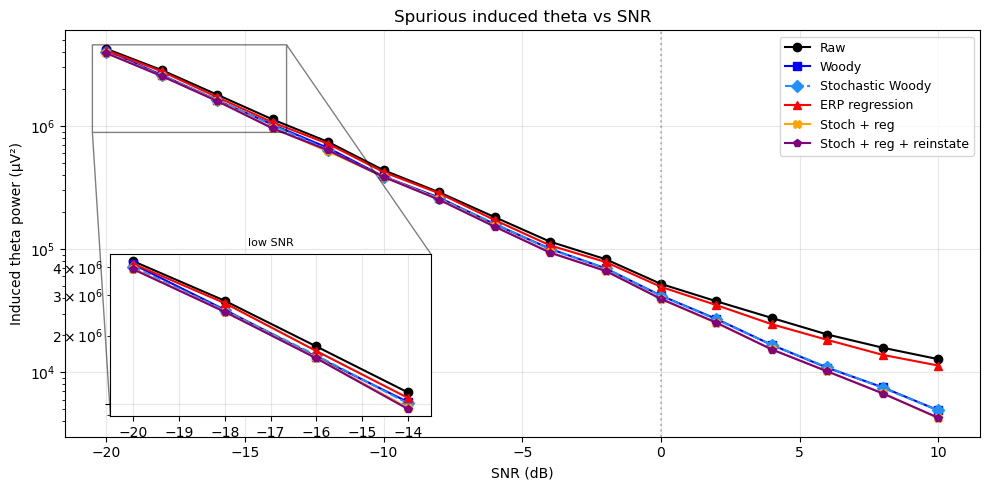

In [18]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.semilogy(target_snr_db, res_raw, 'o-k', label='Raw', linewidth=1.5)
ax.semilogy(target_snr_db, res_woody, 's-b', label='Woody', linewidth=1.5)
ax.semilogy(target_snr_db, res_stoch, 'D--', color='dodgerblue', label='Stochastic Woody', linewidth=1.5)
ax.semilogy(target_snr_db, res_erp_reg, '^-r', label='ERP regression', linewidth=1.5)
ax.semilogy(target_snr_db, res_stoch_reg, 'X-', color='orange', label='Stoch + reg', linewidth=1.5)
ax.semilogy(target_snr_db, res_stoch_reinstate, 'p-', color='purple', label='Stoch + reg + reinstate', linewidth=1.5)

ax.axvline(0, color='gray', linestyle=':', alpha=0.5)
ax.set_xlabel('SNR (dB)')
ax.set_ylabel('Induced theta power (µV²)')
ax.set_title('Spurious induced theta vs SNR')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

axins = ax.inset_axes([0.05, 0.05, 0.35, 0.4])
axins.semilogy(target_snr_db[:4], res_raw[:4], 'o-k', linewidth=1.5)
axins.semilogy(target_snr_db[:4], res_woody[:4], 's-b', linewidth=1.5)
axins.semilogy(target_snr_db[:4], res_stoch[:4], 'D--', color='dodgerblue', linewidth=1.5)
axins.semilogy(target_snr_db[:4], res_erp_reg[:4], '^-r', linewidth=1.5)
axins.semilogy(target_snr_db[:4], res_stoch_reg[:4], 'X-', color='orange', linewidth=1.5)
axins.semilogy(target_snr_db[:4], res_stoch_reinstate[:4], 'p-', color='purple', linewidth=1.5)
axins.set_xlim(target_snr_db[0] - 0.5, target_snr_db[3] + 0.5)
axins.set_yticklabels([])
axins.grid(alpha=0.3)
axins.set_title('low SNR', fontsize=8)

ax.indicate_inset_zoom(axins, edgecolor='black')

plt.tight_layout()